In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def trapez_tensor(n: int) -> np.ndarray:
    K  = np.arange(1, n + 1)[:, None, None]
    Y1 = np.arange(1, n + 1)[None, :, None]
    Y2 = np.arange(1, n + 1)[None, None, :]

    ysum = Y1 + Y2
    ymin = np.minimum(Y1, Y2)
    ymax = np.maximum(Y1, Y2)
    valid = (K <= (ysum - 1))

    val = np.where(K <= ymin, K,
          np.where(K <= ymax, ymin,
          np.where(valid, ysum - K, 0.0)))
    denom = (Y1 * Y2).astype(float)
    T = np.where(valid, val / denom, 0.0)
    return T

# ---------- dormancy/germination update ----------
def f_post_neutral_germination(f_prior, r, g, T):
    """Deterministic neutral model with germination rate g."""
    f_prior = f_prior / f_prior.sum()
    recomb = np.einsum('kij,i,j->k', T, f_prior, f_prior, optimize=True)
    f_new = (1 - r) * f_prior + r * recomb
    f_post = g * f_new + (1 - g) * f_prior
    return f_post / f_post.sum()

def iterate_germination(f0, r, g, T, tol=1e-9, max_iter=1000):
    f = f0 / f0.sum()
    for i in range(max_iter):
        f_new = f_post_neutral_germination(f, r, g, T)
        if np.abs(f_new - f).sum() < tol:
            return f_new, i
        f = f_new
    return f, max_iter

# ---------- theoretical neutral stationary (only for g=1) ----------
def stationary_theory_from_mean(E0: float, n: int) -> np.ndarray:
    y = np.arange(1, n + 1, dtype=float)
    p = y * np.exp(-2.0 * y / E0)
    return p / p.sum()



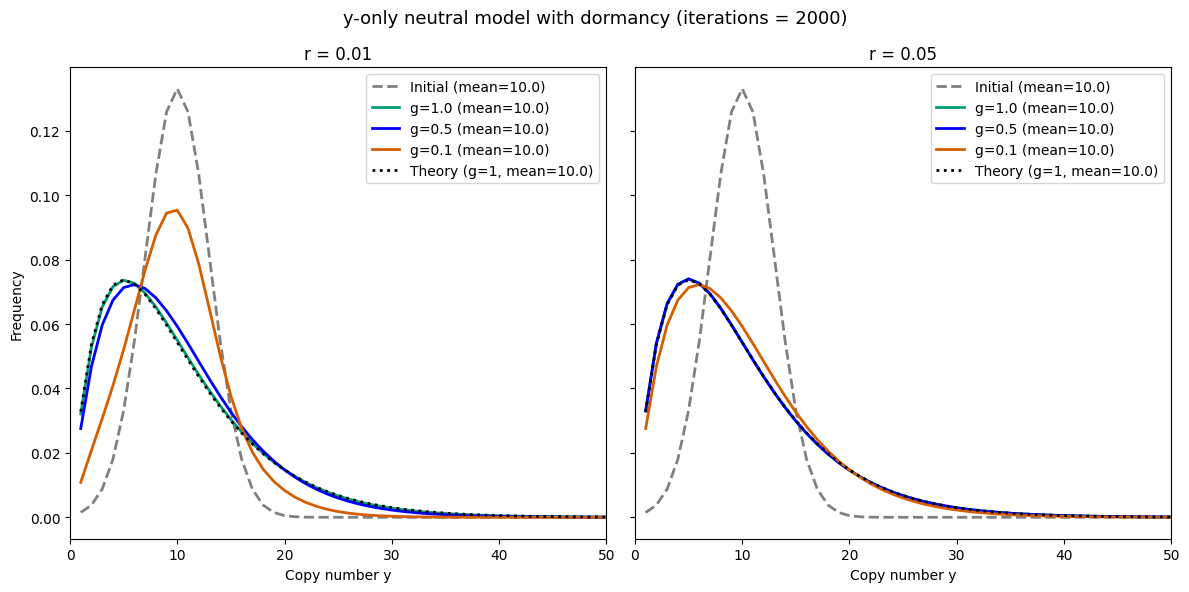

In [10]:
# ---------- run simulation ----------
if __name__ == "__main__":
    n = 80  # maximum copy number considered
    y = np.arange(1, n + 1)
    T = trapez_tensor(n)

    # initial distribution: gaussian around y=10
    f0 = np.exp(-((y - 10.0) ** 2) / (2 * 3.0 ** 2))
    f0 /= f0.sum()

    E0 = np.sum(y * f0)
    theory = stationary_theory_from_mean(E0, n)

    # Initial distribution: bimodal
    # f0 = np.zeros(n)
    # f0[5] = 0.4     # peak at y=6
    # f0[20] = 0.4    # peak at y=21
    # f0 /= f0.sum()
    # E0 = np.sum(y * f0)
    # theory = stationary_theory_from_mean(E0, n)

    recomb_rates = [0.01, 0.05]
    germ_rates = [1.0, 0.5, 0.1]   # 1=no dormancy, smaller g = stronger dormancy
    colors = ["#009E73", "blue", "#D55E00"]

    max_iter = 2000  # if this is your fixed max in iterate_germination

    mean0 = np.sum(y * f0)
    mean_th = np.sum(y * theory)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

    for ax, r in zip(axes, recomb_rates):
        # Initial distribution
        ax.plot(
            y, f0,
            color="gray", linestyle="--", lw=2,
            label=f"Initial (mean={mean0:.1f})"
        )

        # Simulation results for different germination rates
        for g, col in zip(germ_rates, colors):
            f_eq, steps = iterate_germination(f0, r, g, T)
            mean = np.sum(y * f_eq)

            ax.plot(
                y, f_eq,
                color=col, lw=2,
                label=f"g={g} (mean={mean:.1f})"
            )

        # Theory shown for no dormancy case
        ax.plot(
            y, theory,
            color="black", linestyle=":", lw=2,
            label=f"Theory (g=1, mean={mean_th:.1f})"
        )

        ax.set_title(f"r = {r}")
        ax.set_xlabel("Copy number y")
        ax.set_xlim(0, 50)
        ax.legend()

    axes[0].set_ylabel("Frequency")
    fig.suptitle(f"y-only neutral model with dormancy (iterations = 2000)", fontsize=13)
    plt.savefig("y_only_dormancy.png", dpi=300, bbox_inches="tight")
    plt.tight_layout()
    plt.show()
